# Figure 2 — forecast posteriors on the quenched-host fraction

One year of O5, post-O5 and third-generation observations of an all-quenched host
population, analysed with the host-conditioned Poisson--lognormal likelihood.  Section 6 checks
the opposite boundary, $f_{Q,\rm fid}=0$, and section 7 is Table I: the rate of events whose
localization reaches the host-resolvable scale.

Input: `geometry_z0to1.npz` (per-event cylinders) — see `DATA.md`.  The nu and Xi tables
are built here rather than loaded.  Figure:
`figures/fq_posterior_fQ_1_1yr_mocks.{png,pdf}`.

In [1]:
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]

import matplotlib.pyplot as plt
try:
    plt.rcParams.update({
        "text.usetex": True, "font.family": "serif",
        "font.serif": ["Computer Modern Roman"],
        "text.latex.preamble": r"\usepackage{amsmath}", "font.size": 10,
    })
    plt.figure(); plt.title(r"$\alpha$"); plt.close()          # probe
except Exception:
    plt.rcParams.update({"text.usetex": False, "font.size": 10})
    print("LaTeX not available -- falling back to mathtext")
PCT = r"\%" if plt.rcParams["text.usetex"] else "%"

In [2]:
import os, time, json
import numpy as np, pandas as pd
from pathlib import Path
from scipy.special import hyp2f1, gammaln, logsumexp
from scipy.interpolate import RegularGridInterpolator
from astropy.cosmology import FlatLambdaCDM

TRAPZ = np.trapezoid if hasattr(np, "trapezoid") else np.trapz
ROOT  = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
NBDIR = ROOT / "figures"; NBDIR.mkdir(exist_ok=True)

# ---- GW inputs: Fisher-matrix catalogues (z <= 1) and the GWTC-5 default-BBH rate ------------------
# input data: see DATA.md.  Override the location with HOSTINFER_DATA.
DATA   = Path(os.environ.get("HOSTINFER_DATA", ROOT / "data"))
# Only needed to REBUILD data/geometry_z0to1.npz from the Fisher tables (~1 GB, not shipped).
FISHER = Path(os.environ.get("HOSTINFER_FISHER", "fisher_tables"))
FILES = {
    "O5_HLVK30":             "updated_o5_posto5_20260824/gwtc5_default_bbh_n100000_z0to1_o5_updated_20260824_fisher_merged.csv",
    "POSTO5_FIDUCIAL_HLIVK": "updated_o5_posto5_20260824/gwtc5_default_bbh_n100000_z0to1_posto5_fiducial_20260824_fisher_merged.csv",
    "ET+2CE":                "z0to1/gwtc5_default_bbh_n100000_z0to1_fisher_merged.csv",
}
RATES  = FISHER / "z0to1_cumulative_curves.csv"
KEYS   = tuple(FILES)
NAMES  = {"O5_HLVK30": "O5", "POSTO5_FIDUCIAL_HLIVK": "Post-O5", "ET+2CE": "3G"}      # 3G = ET + 2 CE
COLORS = {"O5_HLVK30": "tab:orange", "POSTO5_FIDUCIAL_HLIVK": "tab:green", "ET+2CE": "tab:blue"}

# ---- forecast set-up ---------------------------------------------------------------------------------
F_Q_FID = 1.           # truth: effectively every host quenched (f_Q = 1) in the paper, but we can also test f_Q < 1
YEARS   = (1.0,)
N_MOCK  = 100          # mock data sets per network and observing time
FSKY    = 0.34         # DESI-like footprint (~14,000 deg^2), applied as an event-rate factor
SNR_MIN = 12.0
VBER    = 0.05         # Mpc^3: below this the cylinder holds only the host (host-only limit)
VMAX    = 1e8          # Mpc^3: above this no information, and beyond the w_p fit range -> dropped
SEED    = 20260913

# posterior grid in f_Q: uniform, plus logarithmically dense towards f_Q = 1
FG = np.unique(np.r_[np.linspace(1e-4, 0.99, 2000), 1.0 - np.geomspace(1e-7, 0.01, 800)])

cos = FlatLambdaCDM(H0=70.0, Om0=0.27); h = 0.7; C_KMS = 299792.458

## 1. GW localization → cylinder $\theta^{\rm cyl}=(R_\perp,L_\parallel)$

From each event's Fisher covariance (`cov_ra_ra`, `cov_dec_dec`, `cov_ra_dec`, `cov_dL_dL`), the 90% sky area as a
disc and the half-width of the 90% distance interval:

$$\Delta\Omega_{90}=2\ln10\;\pi\sqrt{\det\Sigma_{(\alpha,\delta)}}\;|\cos\delta|,\qquad
R_\perp=\chi\sqrt{\Delta\Omega_{90}/\pi},$$

$$L_\parallel=1.6449\,\sigma_{D_L}\,\frac{d\chi}{dD_L},\qquad
\frac{d\chi}{dD_L}=\frac{c/H(z)}{\chi+(1+z)\,c/H(z)},\qquad V_{\rm cyl}=2\pi R_\perp^2L_\parallel .$$

The rate $\dot N$ is the all-sky number of SNR $\ge12$ events per year (median of the GWTC-5 rate posterior); every
simulated event carries an equal share of it.

In [3]:
GEOM = DATA / "geometry_z0to1.npz"
if GEOM.exists():                       # shipped product; see DATA.md
    _g = np.load(GEOM)
    G = {k: {q: (_g[f"{k}__{q}"].item() if _g[f"{k}__{q}"].ndim == 0 else _g[f"{k}__{q}"])
             for q in ("R_h", "L_h", "V", "z", "ra", "dec", "ndot", "nsample")} for k in KEYS}
else:                                   # rebuild from the Fisher tables
    cols = ["network_key", "status", "network_snr", "redshift", "ra", "dec", "cov_ra_ra", "cov_dec_dec",
            "cov_ra_dec", "cov_dL_dL", "localization_volume_3d_90_mpc3"]
    rates = pd.read_csv(RATES)
    G = {}
    for key, f in FILES.items():
        d = pd.concat([ch[(ch.network_key == key) & (ch.status == "ok") & (ch.network_snr >= SNR_MIN)]
                       for ch in pd.read_csv(FISHER / f, usecols=cols, chunksize=200_000)])
        d = d[np.isfinite(d.localization_volume_3d_90_mpc3) & (d.localization_volume_3d_90_mpc3 > 0)]
        z = d.redshift.to_numpy(); chi = cos.comoving_distance(z).value; cH = C_KMS / cos.H(z).value
        L = 1.6449 * np.sqrt(d.cov_dL_dL.to_numpy()) * cH / (chi + (1 + z) * cH)                  # Mpc
        det = np.clip((d.cov_ra_ra * d.cov_dec_dec - d.cov_ra_dec ** 2).to_numpy(), 0, None)
        dOm = 2 * np.log(10) * np.pi * np.sqrt(det) * np.abs(np.cos(d.dec.to_numpy()))           # sr
        R = chi * np.sqrt(dOm / np.pi)                                                             # Mpc
        ok = np.isfinite(R) & np.isfinite(L) & (R > 0) & (L > 0)
        r = rates[rates.network_key == key].sort_values("v90_comoving_mpc3").iloc[-1]
        assert int(r.n_sample_le_v90) == len(d)            # same event selection as the rate table
        G[key] = {"R_h": R[ok] * h, "L_h": L[ok] * h,          # h^-1 Mpc, for the clustering model
                  "V": 2 * np.pi * R[ok] ** 2 * L[ok],         # Mpc^3
                  "z": z[ok], "ra": d.ra.to_numpy()[ok], "dec": d.dec.to_numpy()[ok],
                  "ndot": float(r.n_median_1yr), "nsample": len(d)}


print("%-8s %8s %12s %16s %9s %8s %15s" % ("network", "Fisher", "all-sky /yr", "median V_cyl", "median A",
                                          "V>1e8", "used /yr (DESI)"))
for key in KEYS:
    g = G[key]; keep = g["V"] <= VMAX
    print("%-8s %8d %12.1f %11.3g Mpc^3 %9.1f %7.0f%% %15.0f"
          % (NAMES[key], g["nsample"], g["ndot"], np.median(g["V"]), np.median(g["L_h"] / g["R_h"]),
             100 * (1 - keep.mean()), g["ndot"] * FSKY * keep.mean()))

network    Fisher  all-sky /yr     median V_cyl  median A    V>1e8 used /yr (DESI)
O5           5627        388.1    3.33e+07 Mpc^3       8.7      31%              91
Post-O5     25291       1744.3    1.75e+07 Mpc^3      12.6      13%             515
3G          99978       6895.3     7.2e+05 Mpc^3       3.3       0%            2343


## 2. Counts around a host of known type: $w_p$ model and the $\Sigma^D$ closure

Power-law fits to the SDSS bright0 $w_p$
($0.3<r_p<20\ h^{-1}$Mpc, $\pi_{\max}=40$), in $h^{-1}$Mpc. Mean **neighbour** counts around a host of type $h$:

$$\nu^{(h)}_i=\bar n_i\Big[V+2\pi\!\int_0^{R_\perp}\!dr_\perp\,r_\perp\,w^{(L_\parallel)}_{p,hi}(r_\perp)\Big],
\qquad i,h\in\{Q,SF\},$$

with $w_p^{(L)}$ the power law integrated to $|\pi|<L_\parallel$ (closed form in ${}_2F_1$). Covariance:

$$\Sigma^D_{ij}=\delta_{ij}\,\nu^{(h)}_i+\nu^{(h)}_i\nu^{(h)}_j\,\Xi_{ij},\qquad
\Xi_{ij}=\frac1{V^2}\int P(r)\,\xi_{ij}(r)\,dr,$$

where $P(r)$ is the pair-separation distribution of the cylinder ($\int P\,dr=V^2$). The Q–SF cross correlation
follows from the binary-partition identity $\xi_{\rm all}=f_{SF}^2\xi_{SS}+f_Q^2\xi_{QQ}+2f_{SF}f_Q\,\xi_{QSF}$.

In [4]:
# ---- clustering: power-law fits, r0 in h^-1 Mpc (fit range 0.3 < r_p < 20, pi_max = 40) -------------
R0_H  = {"all": 5.972546, "SS": 4.614366, "QQ": 7.364902}
GAMMA = {"all": 1.781478, "SS": 1.587474, "QQ": 1.950136}
f_SF, f_Q = 0.5230905030025009, 0.4769094969974990     # galaxy-population fractions (bright0)
n_tot_h = 0.012702939655410006                          # (h^-1 Mpc)^-3
n_Q, n_SF = f_Q * n_tot_h, f_SF * n_tot_h

def _wp_pl(rp, L, key):
    # 2 int_0^L dpi (sqrt(rp^2+pi^2)/r0)^-gamma, in closed form via 2F1
    g, r0 = GAMMA[key], R0_H[key]
    rp = np.atleast_1d(np.asarray(rp, float)); x = L / rp
    return 2.0 * r0**g * rp**(1-g) * x * hyp2f1(0.5, g/2, 1.5, -x*x)

def wp_model(rp, L, pair):
    if pair == "QQ":   return _wp_pl(rp, L, "QQ")
    if pair == "SFSF": return _wp_pl(rp, L, "SS")
    return (_wp_pl(rp, L, "all") - f_SF**2*_wp_pl(rp, L, "SS")
            - f_Q**2*_wp_pl(rp, L, "QQ")) / (2*f_SF*f_Q)

def excess(Rp, L, pair, nr=800):
    r = np.geomspace(1e-4, Rp, nr)
    return 2*np.pi*TRAPZ(r*wp_model(r, L, pair), r)

def means(Rp, L):
    V = 2*np.pi*Rp**2*L
    out = {"V": V, "Nbar": np.array([n_Q*V, n_SF*V])}
    for H, pairs in (("Q", ("QQ", "QSF")), ("SF", ("QSF", "SFSF"))):
        nu = np.array([n_Q*(V + excess(Rp, L, pairs[0])),
                       n_SF*(V + excess(Rp, L, pairs[1]))])
        out[H] = {"nu": nu, "e": np.array([1.0, 0.0]) if H == "Q" else np.array([0.0, 1.0])}
    return out

# ---- cylinder pair kernel: G(r_perp, s_par) = A2(r_perp) T1(s_par) -----------------------------------------
def A2(d, Rp):
    d = np.clip(np.asarray(d), 0, None); x = np.clip(d/(2*Rp), 0, 1)
    return np.where(d < 2*Rp, 2*Rp**2*np.arccos(x)
                    - (d/2)*np.sqrt(np.clip(4*Rp**2-d**2, 0, None)), 0.0)

def T1(s, L):
    s = np.abs(np.asarray(s)); return np.where(s < 2*L, 2*L - s, 0.0)

def pair_grid(Rp, L, nr=4000, nt=400):
    t, wt = np.polynomial.legendre.leggauss(nt)
    t = 0.5*np.pi*(0.5*(t+1.0)); wt = wt*0.25*np.pi
    r = np.geomspace(1e-6*min(Rp, L), np.hypot(2*Rp, 2*L), nr)
    g = (np.sin(t)[None,:] * A2(r[:,None]*np.sin(t)[None,:], Rp)
                           * T1(r[:,None]*np.cos(t)[None,:], L))
    return r, 4*np.pi*r**2*(g*wt[None,:]).sum(axis=1)

def xi_pl(r, key): return (np.asarray(r)/R0_H[key])**(-GAMMA[key])

def xi_pair(r, pair):
    if pair == "QQ":   return xi_pl(r, "QQ")
    if pair == "SFSF": return xi_pl(r, "SS")
    return (xi_pl(r,"all") - f_SF**2*xi_pl(r,"SS") - f_Q**2*xi_pl(r,"QQ"))/(2*f_SF*f_Q)

def Xi_matrix(Rp, L):
    r, P = pair_grid(Rp, L); V = 2*np.pi*Rp**2*L
    M = np.empty((2,2))
    for a, pa in ((0,"QQ"), (1,"SFSF")):
        M[a,a] = TRAPZ(P*xi_pair(r,pa)*r, np.log(r))/V**2
    M[0,1] = M[1,0] = TRAPZ(P*xi_pair(r,"QSF")*r, np.log(r))/V**2
    return M

### Tabulating $\nu^{(h)}$ and $\Xi$

A mock holds $10^2$–$10^4$ events, so $\nu^{(h)}$ and $\Xi$ are tabulated once on $46\times52$ points in
$(\ln R_\perp,\ln L_\parallel)$, $R_\perp\in[0.02,300]$, $L_\parallel\in[0.02,3000]\ h^{-1}$Mpc, and interpolated
linearly in the logarithms. In the corner $R_\perp\le0.038$, $L_\parallel\lesssim0.13\ h^{-1}$Mpc the power-law
extrapolation (far below the fit range) makes some entries non-positive; they are floored so that the
log-interpolation stays finite. No event with $V_{\rm cyl}\ge0.05\ \rm Mpc^3$ reaches that corner.

In [5]:
t0 = time.time()
lR = np.linspace(np.log(0.02), np.log(300), 46); lL = np.linspace(np.log(0.02), np.log(3000), 52)
NUQ = np.empty((len(lR), len(lL), 2)); NUS = np.empty_like(NUQ); XI = np.empty((len(lR), len(lL), 3))
for a, r in enumerate(np.exp(lR)):
    for b, l in enumerate(np.exp(lL)):
        m = means(float(r), float(l)); X = Xi_matrix(float(r), float(l))
        NUQ[a, b] = m["Q"]["nu"]; NUS[a, b] = m["SF"]["nu"]; XI[a, b] = [X[0, 0], X[0, 1], X[1, 1]]
print("tables built in %.0f s; non-positive entries (corner only): nu %d, Xi %d"
      % (time.time() - t0, (NUQ <= 0).sum() + (NUS <= 0).sum(), (XI <= 0).sum()))

class Tables:
    """(R_perp, L_par) in h^-1 Mpc  ->  nu^(Q), nu^(SF) (n, 2) and Xi (n, 2, 2)"""
    def __init__(self):
        mk = lambda A: RegularGridInterpolator((lR, lL), np.log(np.clip(A, 1e-30, None)),
                                               bounds_error=False, fill_value=None)
        self.fq = [mk(NUQ[:, :, i]) for i in (0, 1)]
        self.fs = [mk(NUS[:, :, i]) for i in (0, 1)]
        self.fx = [mk(XI[:, :, i]) for i in (0, 1, 2)]
    def __call__(self, R, L):
        p = np.column_stack([np.clip(np.log(R), lR[0], lR[-1]), np.clip(np.log(L), lL[0], lL[-1])])
        nuQ = np.column_stack([np.exp(f(p)) for f in self.fq])
        nuS = np.column_stack([np.exp(f(p)) for f in self.fs])
        x = [np.exp(f(p)) for f in self.fx]
        Xm = np.empty((len(R), 2, 2)); Xm[:, 0, 0] = x[0]; Xm[:, 0, 1] = Xm[:, 1, 0] = x[1]; Xm[:, 1, 1] = x[2]
        return nuQ, nuS, Xm

tb = Tables()

# spot check against the direct calculation at randomly chosen catalogue events
rng_chk = np.random.default_rng(0); worst = 0.0
for key in KEYS:
    g = G[key]; ok = (g["V"] >= VBER) & (g["V"] <= VMAX)
    for i in rng_chk.choice(np.flatnonzero(ok), 5, replace=False):
        m = means(g["R_h"][i], g["L_h"][i]); X = Xi_matrix(g["R_h"][i], g["L_h"][i])
        nq, ns, xm = tb(g["R_h"][i:i+1], g["L_h"][i:i+1])
        worst = max(worst, np.abs(nq[0] / m["Q"]["nu"] - 1).max(), np.abs(ns[0] / m["SF"]["nu"] - 1).max(),
                    np.abs(xm[0] / X - 1).max())
print("interpolated vs direct nu and Xi at 15 catalogue events: worst relative error %.1e" % worst)

tables built in 619 s; non-positive entries (corner only): nu 32, Xi 18
interpolated vs direct nu and Xi at 15 catalogue events: worst relative error 1.5e-03


## 3. Per-event likelihoods $p(\mathbf N\mid Q)$ and $p(\mathbf N\mid SF)$

Bivariate Poisson–lognormal, moment-matched to $(\boldsymbol\nu^{(h)},\Sigma^D)$:

$$\mathbf x\sim\mathcal N\!\big(-\tfrac12\,\mathrm{diag}\,S,\ S\big),\qquad
S_{ij}=\ln\!\Big[1+\frac{\Sigma_{ij}-\delta_{ij}\nu_i}{\nu_i\nu_j}\Big]=\ln(1+\Xi_{ij}),\qquad
n_i\mid\mathbf x\sim\mathrm{Poisson}(\nu_i e^{x_i}),$$

which reproduces the mean and the full covariance, including the Q–SF cross term. The host is counted in its own
type, $\mathbf N=\mathbf n+\mathbf e_h$, so

$$p(\mathbf N\mid Q)=p_{\rm PLN}\big(\mathbf N-\mathbf e_Q\,\big|\,\boldsymbol\nu^{(Q)},S^{(Q)}\big),\qquad
p(\mathbf N\mid SF)=p_{\rm PLN}\big(\mathbf N-\mathbf e_{SF}\,\big|\,\boldsymbol\nu^{(SF)},S^{(SF)}\big),$$

and zero if a component would be negative. The pmf is a 2-D integral over $\mathbf x$, done per event by
**mode-centred adaptive Gauss–Hermite** quadrature ($20\times20$ nodes around the Laplace mode, scaled by the local
curvature). For $V_{\rm cyl}<0.05\ \rm Mpc^3$ the host-only limit
$p(\mathbf N\mid h)=\delta_{h,h_{\rm true}}$ is used (fewer than one such event in 3 yr, even for 3G).

In [6]:
def gh_nodes(ng):
    """Gauss-Hermite nodes and log weights for the 2-D latent integral"""
    z, w = np.polynomial.hermite_e.hermegauss(ng)
    Z1, Z2 = np.meshgrid(z, z, indexing="ij")
    Zn = np.column_stack([Z1.ravel(), Z2.ravel()])
    return Zn, np.log(np.outer(w, w).ravel()) + 0.5*(Zn**2).sum(1)

NODES = gh_nodes(20)

def sigmaD(nu, XI):
    return nu[:, :, None]*np.eye(2)[None] + nu[:, :, None]*nu[:, None, :]*XI

def S_of(nu, Sig):
    return np.log(1.0 + (Sig - nu[:, :, None]*np.eye(2)[None]) / (nu[:, :, None]*nu[:, None, :]))

def logpmf_batch(n, nu, S, iters=30, chunk=4000, nodes=NODES):
    """ln p_PLN(n | nu, S); every row has its own nu (2,) and S (2,2)."""
    Zn, Lw = nodes
    n = np.asarray(n, float); out = np.empty(len(n))
    for k in range(0, len(n), chunk):
        sl = slice(k, min(k+chunk, len(n))); nn, vv, SS = n[sl], nu[sl], S[sl]
        Si = np.linalg.inv(SS); m = -0.5*np.stack([SS[:, 0, 0], SS[:, 1, 1]], 1); ldS = np.linalg.slogdet(SS)[1]
        x = np.log((nn + 0.5)/vv)
        for _ in range(iters):                                   # Newton iteration to the mode of the integrand
            e = vv*np.exp(x)
            g = nn - e - np.einsum("mij,mj->mi", Si, x - m)
            H = -(e[:, :, None]*np.eye(2)[None] + Si)
            x = x - np.linalg.solve(H, g[:, :, None])[:, :, 0]
        e = vv*np.exp(x)
        Cv = np.linalg.inv(e[:, :, None]*np.eye(2)[None] + Si); Lc = np.linalg.cholesky(Cv)
        X = x[:, None, :] + np.einsum("mij,gj->mgi", Lc, Zn)     # nodes around the mode, scaled by the curvature
        lam = vv[:, None, :]*np.exp(X)
        po = (nn[:, None, :]*np.log(lam) - lam - gammaln(nn[:, None, :] + 1)).sum(2)
        dx = X - m[:, None, :]
        q = np.einsum("mgi,mij,mgj->mg", dx, Si, dx)
        lg = po - 0.5*q - np.log(2*np.pi) - 0.5*ldS[:, None]
        out[sl] = 0.5*np.linalg.slogdet(Cv)[1] + logsumexp(lg + Lw[None, :], axis=1)
    return out

def sample_batch(nu, S, rng):
    L = np.linalg.cholesky(S)
    x = -0.5*np.stack([S[:, 0, 0], S[:, 1, 1]], 1) + np.einsum("mij,mj->mi", L, rng.standard_normal((len(nu), 2)))
    return rng.poisson(nu*np.exp(x))

### Checking the quadrature

The default $20\times20$ mode-centred grid is compared with a denser one, and the pmf is
summed over a growing range of counts.

In [7]:
NS = np.array([[0, 0], [1, 0], [3, 1], [10, 2], [40, 8], [5, 20], [150, 30]])

for Rc, Lc in ((0.5, 5.0), (2.0, 30.0)):                       # h^-1 Mpc
    nuQ, _, Xc = tb(np.array([Rc]), np.array([Lc]))
    Sc = S_of(nuQ, sigmaD(nuQ, Xc))[0]
    rep = lambda A, k: (np.repeat(nuQ, k, 0), np.repeat(Sc[None], k, 0))

    ref = logpmf_batch(NS, *rep(NS, len(NS)), nodes=gh_nodes(40))
    dev = [np.abs(logpmf_batch(NS, *rep(NS, len(NS)), nodes=gh_nodes(ng)) - ref).max()
           for ng in (10, 20)]

    tot = []                                                   # sum_N p(N) over a growing range
    for fac in (3, 6, 12):
        K = int(np.ceil(fac*nuQ[0].max())) + 5
        grid = np.stack(np.meshgrid(np.arange(K), np.arange(K), indexing="ij"), -1).reshape(-1, 2)
        tot.append(np.exp(logsumexp(logpmf_batch(grid, *rep(grid, len(grid))))))

    print("R_perp=%3.1f L_par=%4.1f h^-1 Mpc  nu=(%.2f, %.2f) | max |ln p - ln p(40 nodes)|: "
          "10 nodes %.1e, 20 nodes %.1e | sum_N p(N) over 3/6/12 x nu_max: %s"
          % (Rc, Lc, *nuQ[0], dev[0], dev[1], "  ".join("%.6f" % t for t in tot)))

R_perp=0.5 L_par= 5.0 h^-1 Mpc  nu=(2.74, 0.91) | max |ln p - ln p(40 nodes)|: 10 nodes 1.1e-04, 20 nodes 8.5e-06 | sum_N p(N) over 3/6/12 x nu_max: 0.961782  0.978147  0.989449


R_perp=2.0 L_par=30.0 h^-1 Mpc  nu=(16.29, 10.87) | max |ln p - ln p(40 nodes)|: 10 nodes 4.3e-06, 20 nodes 7.7e-10 | sum_N p(N) over 3/6/12 x nu_max: 0.949078  0.987878  0.998064


## 4. Mock data sets and the posterior of $f_Q$

For an observing time $T$: $N_{\rm ev}\sim\mathrm{Poisson}\big(T\,\dot N\,f_{\rm sky}\,\epsilon_V\big)$, with
$\epsilon_V$ the fraction of events with $V_{\rm cyl}\le10^8\ \rm Mpc^3$; events are drawn with replacement from the
Fisher sample. Each host is Q with probability $f_{Q,\rm fid}$; its neighbour counts are drawn from the PLN of its
**true** type and the host is added. Each mock is then scored with

$$\ln\mathcal L(f_Q)=\sum_{i=1}^{N_{\rm ev}}\ln\!\big[f_Q\,p(\mathbf N_i\mid Q)+(1-f_Q)\,p(\mathbf N_i\mid SF)\big],
\qquad p(f_Q\mid\mathrm{data})\propto\mathcal L(f_Q)\quad(\text{flat prior on }[0,1]).$$

* **expected posterior** — from the mean of $\ln\mathcal L$ over the mocks (an Asimov-type data set);
* **mock scatter** — the 16–84% range, over the mock data sets, of the limits from each mock's own posterior
  (how much a single realisation of the data moves the result);
* the limits are the 90% one-sided limits of that posterior, $P(f_Q>\text{lower})=P(f_Q<\text{upper})=0.9$.
  With the truth at a boundary only one of the two says anything — a lower limit at $f_{Q,\rm fid}=1$, an upper
  limit at $0$ — and an equal-tailed interval would exclude the truth once the tail is squeezed against it.

In [8]:
def event_loglikes(r, l, v, isQ, rng):
    """Draw each event's counts under its TRUE host type; return ln p(N|Q) and ln p(N|SF)."""
    n = len(v); lq = np.full(n, -np.inf); ls = np.full(n, -np.inf)
    ber = v < VBER                                                    # host-only limit
    lq[ber & isQ] = 0.0; ls[ber & ~isQ] = 0.0
    pl = ~ber
    if pl.any():
        nuQ, nuS, Xe = tb(r[pl], l[pl])
        SQ, SS = S_of(nuQ, sigmaD(nuQ, Xe)), S_of(nuS, sigmaD(nuS, Xe))
        q = isQ[pl]
        N = sample_batch(np.where(q[:, None], nuQ, nuS), np.where(q[:, None, None], SQ, SS), rng) \
            + np.where(q[:, None], [[1, 0]], [[0, 1]])                # neighbours + the host itself
        a = N - np.array([1, 0]); b = N - np.array([0, 1])            # neighbours if the host were Q / SF
        okq = (a >= 0).all(1); oks = (b >= 0).all(1)
        tq = np.full(pl.sum(), -np.inf); ts = np.full(pl.sum(), -np.inf)
        if okq.any(): tq[okq] = logpmf_batch(a[okq], nuQ[okq], SQ[okq])
        if oks.any(): ts[oks] = logpmf_batch(b[oks], nuS[oks], SS[oks])
        lq[pl] = tq; ls[pl] = ts
    return lq, ls

def loglike_grid(lq, ls, chunk=256):
    """ln L(f_Q) = sum_i ln[f_Q p(N_i|Q) + (1 - f_Q) p(N_i|SF)] on the grid FG"""
    lf, l1f = np.log(FG), np.log1p(-FG); out = np.empty(len(FG))
    for k in range(0, len(FG), chunk):
        s = slice(k, k + chunk)
        out[s] = np.logaddexp(lf[s, None] + lq[None, :], l1f[s, None] + ls[None, :]).sum(1)
    return out

def run_mocks(key, T, seed, fq_fid=None):
    """N_MOCK mock data sets for one network and observing time.
    fq_fid overrides the fiducial quenched-host fraction."""
    g = G[key]; use = g["V"] <= VMAX
    rate = T * g["ndot"] / g["nsample"] * FSKY                        # expected events per simulated event
    mean_n = rate * use.sum()
    Rh, Lh, V, z = g["R_h"][use], g["L_h"][use], g["V"][use], g["z"][use]
    rng = np.random.default_rng(seed)
    fq = F_Q_FID if fq_fid is None else fq_fid
    LL = np.empty((N_MOCK, len(FG)))
    nev = np.empty(N_MOCK, int)
    for m in range(N_MOCK):
        n = rng.poisson(mean_n); i = rng.integers(0, len(V), n)
        isQ = rng.random(n) < fq
        lq, ls = event_loglikes(Rh[i], Lh[i], V[i], isQ, rng)
        LL[m] = loglike_grid(lq, ls)
        nev[m] = n
    return {"LL": LL, "n_events": nev, "mean_n": mean_n}

def posterior(ll):
    p = np.exp(ll - ll.max()); return p / TRAPZ(p, FG)

def credible_limits(p, q=0.9):
    """(lower, upper) with P(f_Q > lower) = P(f_Q < upper) = q"""
    c = np.r_[0.0, np.cumsum(0.5*(p[1:] + p[:-1])*np.diff(FG))]; c /= c[-1]
    return float(np.interp(1 - q, c, FG)), float(np.interp(q, c, FG))

def print_limits(LLs, fq_fid, q=0.9):
    """Limits of the expected posterior, with the 16-84% range over the mock data sets.
    Both sides are quoted unless the truth sits at a boundary, where only one is informative."""
    print("%g%% credible limits, f_Q,fid = %g   (expected | mocks median [16-84%%])"
          % (100*q, fq_fid))
    for key, LL in LLs.items():
        lo, hi = credible_limits(posterior(LL.mean(0)), q)
        sp = np.array([credible_limits(posterior(ll), q) for ll in LL])
        for j, (sign, lim) in enumerate(((">", lo), ("<", hi))):
            if (fq_fid > 0) if j == 0 else (fq_fid < 1):
                w = np.percentile(sp[:, j], [16, 50, 84])
                print(f"{NAMES[key]:9s}: f_Q {sign} {lim:.3f}   |  "
                      f"{w[1]:.3f} [{w[0]:.3f}, {w[2]:.3f}]")

In [9]:
t0 = time.time(); RES = {}
for T in YEARS:
    for k, key in enumerate(KEYS):
        RES[(key, T)] = run_mocks(key, T, seed=SEED + 1000*k + int(10*T))
        print("%-8s %g yr: <N_ev> in the footprint = %5.0f   (%d mocks, %3.0f s elapsed)"
              % (NAMES[key], T, RES[(key, T)]["mean_n"], N_MOCK, time.time() - t0))

O5       1 yr: <N_ev> in the footprint =    91   (100 mocks,   1 s elapsed)
Post-O5  1 yr: <N_ev> in the footprint =   515   (100 mocks,   5 s elapsed)
3G       1 yr: <N_ev> in the footprint =  2343   (100 mocks,  24 s elapsed)


## 5. Result

90% credible limits, f_Q,fid = 1   (expected | mocks median [16-84%])
O5       : f_Q > 0.227   |  0.189 [0.111, 0.369]
Post-O5  : f_Q > 0.502   |  0.476 [0.269, 0.645]
3G       : f_Q > 0.920   |  0.920 [0.887, 0.939]


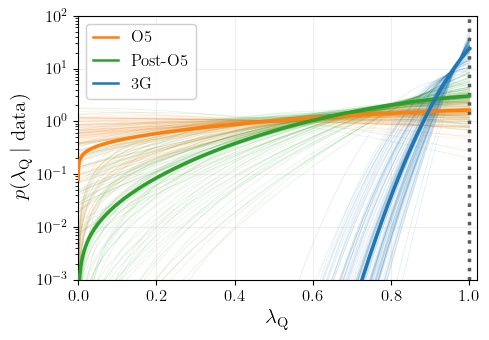

In [10]:
from matplotlib.lines import Line2D

T = 1                                                          # one year of observation

fig, ax = plt.subplots(figsize=(5.0, 3.5))
for key in KEYS:
    LL = RES[(key, T)]["LL"]                                   # (mock universes, f_Q grid)
    for ll in LL:                                              # one line per mock universe
        ax.plot(FG, posterior(ll), color=COLORS[key], lw=0.6, alpha=0.12, zorder=1)
    ax.plot(FG, posterior(LL.mean(0)), color=COLORS[key], lw=2.6, zorder=3)   # expected posterior

#ax.set_xscale("log")
ax.set_xlim(0, 1.02)
ax.set_yscale("log"); ax.set_ylim(1e-3, 100.)
ax.tick_params(axis="both", labelsize=12)
ax.set_xlabel(r"$\lambda_{\rm Q}$", fontsize=15)
ax.set_ylabel(r"$p(\lambda_{\rm Q}\mid\mathrm{data})$", fontsize=15)
ax.grid(alpha=0.2)
ax.axvline(1.0, color="0.35", lw=2.5, ls=":", zorder=2)        # value the mock data were drawn at

handles = [Line2D([0], [0], color=COLORS[k], lw=1.8, label=NAMES[k]) for k in KEYS]
ax.legend(handles=handles, loc="upper left", fontsize=12, framealpha=0.93,
          edgecolor="0.8", handlelength=1.5)

print_limits({k: RES[(k, T)]["LL"] for k in KEYS}, F_Q_FID)

fig.tight_layout()
for e in ("png", "pdf"):
    fig.savefig(NBDIR / ("fq_posterior_fQ_1_1yr_mocks.%s" % e), dpi=200, bbox_inches="tight")
plt.show()

## 6. Another fiducial quenched fraction

The same mocks with $f_{Q,\rm fid}$ set to anything else.  `print_limits` quotes both 90%
limits, dropping the side that carries no information when the truth sits at a boundary: only
a lower limit at $f_{Q,\rm fid}=1$, only an upper limit at $0$.

In [11]:
FQ_ALT = 0.0                                                   # any value in [0, 1]

RES_ALT = {key: run_mocks(key, T, seed=SEED + 1000*k + int(10*T) + 3, fq_fid=FQ_ALT)
           for k, key in enumerate(KEYS)}                      # +3: a stream of its own

print_limits({k: v["LL"] for k, v in RES_ALT.items()}, FQ_ALT)

90% credible limits, f_Q,fid = 0   (expected | mocks median [16-84%])
O5       : f_Q < 0.795   |  0.830 [0.656, 0.909]
Post-O5  : f_Q < 0.504   |  0.508 [0.354, 0.771]
3G       : f_Q < 0.098   |  0.098 [0.072, 0.131]


## 7. Table I — events reaching the host-resolvable scale

A localization resolves the host galaxy when its cylinder holds the host and little else,
$\sum_{h'}\bar N_{h'\mid h}(\theta^{\rm cyl})=1$ mean neighbour.  Each event is tested on its own
$(R_\perp,L_\parallel)$, so no fiducial cylinder shape enters; at the aspect ratio
$A=L_\parallel/R_\perp=5$ of the best-localized events the condition corresponds to the volume
$V_{\rm res}$ printed below.  Rates are all-sky detections per year times $f_{\rm sky}$, as above.

In [12]:
from scipy.optimize import brentq

A_FID = 5.0                                   # fiducial aspect ratio

def V_res(host, A=A_FID):
    """cylinder volume [Mpc^3] holding one mean neighbour of a host of type `host`"""
    def one(V):                               # V in (h^-1 Mpc)^3
        R = (V / (2*np.pi*A))**(1/3)
        return means(R, A*R)[host]["nu"].sum() - 1.0
    return brentq(one, 1e-6, 1e5) / h**3

print("V_res at A = %.0f:  Q host %.2f Mpc^3,  SF host %.1f Mpc^3\n"
      % (A_FID, V_res("Q"), V_res("SF")))
print("%-8s %12s %12s   (events/yr, f_sky = %.2f)" % ("network", "Q host", "SF host", FSKY))
for key in KEYS:
    g = G[key]
    nuQ, nuS = tb(g["R_h"], g["L_h"])[:2]                     # mean neighbour counts of each event
    w = g["ndot"] / len(g["R_h"]) * FSKY                      # events per year per catalogue event
    print("%-8s %12.3f %12.3f" % (NAMES[key], (nuQ.sum(1) < 1).sum() * w, (nuS.sum(1) < 1).sum() * w))

V_res at A = 5:  Q host 0.46 Mpc^3,  SF host 7.4 Mpc^3

network        Q host      SF host   (events/yr, f_sky = 0.34)
O5              0.000        0.070
Post-O5         0.117        0.211
3G              0.703        3.236
